# Webcam Mini Project
Build your own webcam image classifier on the cifar100 dataset.

This mini project has two parts.

**Part A** is the groundwork: you build and train a simple neural network on an existing image dataset.

**Part B** puts that network to use: you capture an image with your webcam and let the network predict the photographed object. This can grow into a standalone app you publish on GitHub.

Follow the steps below in order.

## Part A
### 1. Imports

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras import backend as K
from tensorflow.keras import Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, Dense, MaxPooling2D, Flatten

from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical


import tensorflow_datasets as tfds

### 2. Load and preprocess dataset
In case your RAM is too small, consider using cifar10 instead of cifar100.

In [2]:
# try_gcs=True loads the prepared dataset from the TensorFlow Datasets
# Google Cloud Storage mirror instead of the original cs.toronto.edu
# server, which is often overloaded and slow to respond.
(ds_train, ds_test), ds_info = tfds.load(
    "cifar100",
    split=["train", "test"],
    as_supervised=True,
    batch_size=-1,
    with_info=True,
    try_gcs=True,
)

X_train, y_train = tfds.as_numpy(ds_train)
X_test, y_test = tfds.as_numpy(ds_test)

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

class_names = ds_info.features["label"].names

print("Training:", X_train.shape)
print("Test:", X_test.shape)

c:\Users\justu\OneDrive\Dokumente\neueFische\Woche_09\Uebungen\ds_image_classification_mini_project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dl Completed...: 0 url [00:00, ? url/s]
Dl Completed...: 100%|██████████| 1/1 [30:25<00:00, 1823.88s/ url]

Dl Completed...: 100%|██████████| 1/1 [30:25<00:00, 1825.21s/ url]


Dataset cifar100 downloaded and prepared to C:\Users\justu\tensorflow_datasets\cifar100\3.0.2. Subsequent calls will reuse this data.



Training: (50000, 32, 32, 3)
Test: (10000, 32, 32, 3)


In [3]:
X_train[0]

array([[[0.5921569 , 0.6039216 , 0.5686275 ],
        [0.5647059 , 0.5764706 , 0.5294118 ],
        [0.5529412 , 0.56078434, 0.5254902 ],
        ...,
        [0.17254902, 0.14901961, 0.15294118],
        [0.4392157 , 0.39215687, 0.3764706 ],
        [0.5686275 , 0.49803922, 0.47058824]],

       [[0.6       , 0.6117647 , 0.5882353 ],
        [0.5529412 , 0.5647059 , 0.5294118 ],
        [0.54509807, 0.5568628 , 0.53333336],
        ...,
        [0.26666668, 0.23137255, 0.23137255],
        [0.5137255 , 0.44313726, 0.41568628],
        [0.4745098 , 0.39607844, 0.36862746]],

       [[0.6392157 , 0.64705884, 0.6313726 ],
        [0.5882353 , 0.6       , 0.5686275 ],
        [0.5764706 , 0.58431375, 0.5647059 ],
        ...,
        [0.29411766, 0.25882354, 0.23529412],
        [0.39607844, 0.3372549 , 0.3019608 ],
        [0.3254902 , 0.3019608 , 0.28627452]],

       ...,

       [[0.5882353 , 0.5882353 , 0.63529414],
        [0.2       , 0.20392157, 0.2627451 ],
        [0.18039216, 0

### 3. Build a **Simple** CNN  

*Suggestion* for the architecture:
1. Convolutional layer with 32 3 by 3 filters and ReLu activation
2. Maxpooling to halve the dimension (what should the pool_size in this case?)
3. Dropout 25%
4. Convolutional layer with 64 filters (the rest as above)
5. Maxpooling (repeat no. 2)
6. Dropout 25%
7. Convolutional layer with 128 filters (the rest as above)
8. Flatten the resulting feature map (no parameters)
9. Dense layer with 512 neurons and relu activation
10. Dropout 50%
11. Softmax dense output layer (how many neurons should it have? How many classes should be predicted?)  

Please look at the following documentation for the right syntax:
+ [**Sequential**](https://www.tensorflow.org/api_docs/python/tf/keras/models/Sequential)
+ [**Input**](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Input)
+ [**Conv2D**](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Conv2D)
+ [**MaxPool2D**](https://www.tensorflow.org/api_docs/python/tf/keras/layers/MaxPool2D)
+ [**Flatten**](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Flatten)
+ [**Dense**](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dense)

In [92]:
# in case you want to rebuild it, clear the previous one first:
# K.clear_session()

K.clear_session()  # Cache der Modellparameter leeren
model = Sequential(
    [   
        
       Input(shape=(32,32,3)),
       layers.RandomFlip("horizontal"),
       Conv2D(32,3,
                  activation = "relu",
                  padding = "same"),
        layers.BatchNormalization(),
       Conv2D(32,3,
                         activation = "relu",
                         padding = "same"),
        layers.BatchNormalization(),
       MaxPooling2D(pool_size = (2,2) ),
       layers.Dropout(0.25),
       Conv2D(64,3,
               activation = "relu",
               padding = "same"),
        layers.BatchNormalization(),
       Conv2D(64,3,
                      activation = "relu",
                      padding = "same"),
        layers.BatchNormalization(),
       MaxPooling2D(pool_size= (2,2)),
       layers.Dropout(0.25),
       
       Conv2D(128,3,
               activation="relu",
               padding = "same"),
        layers.BatchNormalization(),
       Conv2D(128,3,
              padding = "same",
              activation = "relu"),
        layers.BatchNormalization(),
       MaxPooling2D(pool_size = (2,2)),
       layers.Dropout(0.25),
       Flatten(),
       layers.Dense(units = 512, activation  = "relu"),
       layers.Dropout(0.5),
       layers.Dense(units = 100, activation = "softmax"),
        

    ])
    # layers.Conv2D()
    # layers....,
    # layers....,

    # layers....,
    # layers.Flatten(),
    # layers.Dense(...),
    # layers.Dropout(...),
    # layers.Dense(units=10, activation="softmax")  # output layer for 100 classes


In [93]:
# model architecture summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             

 Total params: 1,389,188 (5.30 MB)

 Trainable params: 1,388,292 (5.30 MB)

 Non-trainable params: 896 (3.50 KB)

### 4. Compile the Model  
- Use the 'adam' optimizer
- 'sparse_categorical_crossentropy' loss
- Chose 'accuracy' as the metric

The optimiser controls how the weights are updated from the gradients: `adam` is a robust default that adapts the step size per parameter. The loss is `sparse_categorical_crossentropy` because the labels are stored as single integers (0 to 99) rather than one-hot vectors; the sparse version reads those integers directly. Tracking `accuracy` gives a human-readable score alongside the loss.

In [94]:
model.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

### 5. Train the Model  

- select 10 epochs  
- a batch size of 64  
- use 20% of the training data for validation
The synatax can be found [**here**](https://www.tensorflow.org/api_docs/python/tf/keras/Model#fit).

In [95]:
epochs = 30

history = model.fit(
    X_train, y_train, batch_size=64, epochs=epochs, validation_split=0.2
)

Epoch 1/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 48s 72ms/step - accuracy: 0.0595 - loss: 4.3053 - val_accuracy: 0.1336 - val_loss: 3.7143
Epoch 2/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 46s 73ms/step - accuracy: 0.1173 - loss: 3.7876 - val_accuracy: 0.1631 - val_loss: 3.5552
Epoch 3/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 47s 76ms/step - accuracy: 0.1617 - loss: 3.4971 - val_accuracy: 0.2293 - val_loss: 3.1076
Epoch 4/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 47s 75ms/step - accuracy: 0.2006 - loss: 3.2597 - val_accuracy: 0.2895 - val_loss: 2.8322
Epoch 5/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 47s 76ms/step - accuracy: 0.2371 - loss: 3.0442 - val_accuracy: 0.2994 - val_loss: 2.7274
Epoch 6/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 56s 89ms/step - accuracy: 0.2715 - loss: 2.8894 - val_accuracy: 0.3383 - val_loss: 2.5825
Epoch 7/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 69s 111ms/step - accuracy: 0.2985 - loss: 2.7264 - val_accuracy: 0.3655 - val_loss: 2.4495
Epoch 8/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 73s 117ms/step - accuracy: 0.3252 - loss: 2.5940 

### 6. Evaluate the Model  

Don't worry about the poor accuracy at the moment.

In [96]:
# in numbers
test_loss, test_acc = model.evaluate(X_test,y_test, verbose=2)
print(f'Test accuracy: {test_acc:.4f}')

313/313 - 4s - 11ms/step - accuracy: 0.5815 - loss: 1.5258
Test accuracy: 0.5815


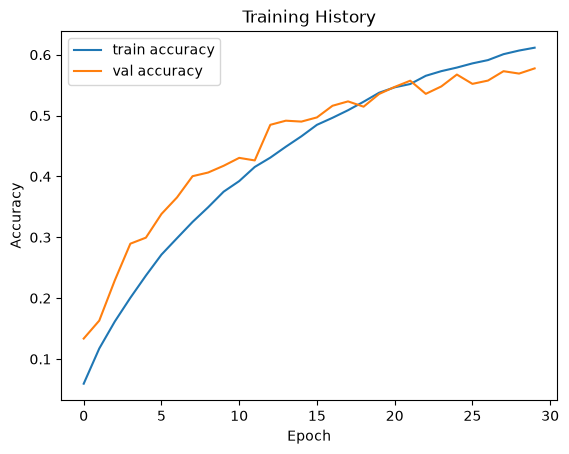

In [99]:
# in a plot
plt.plot(history.history['accuracy'], label='train accuracy')
plt.plot(history.history['val_accuracy'], label='val accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training History')
plt.show()

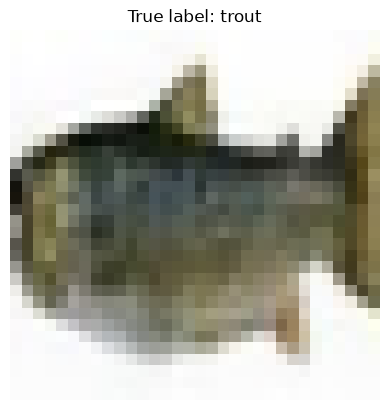

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


In [159]:
# Do some random predictions on some images of the test portion
idx = np.random.randint(len(X_test))
plt.imshow(np.squeeze(X_test[idx]))
plt.title(f'True label: {class_names[y_test[idx].item()]}')
plt.axis('off')
plt.show()

pred = model.predict(X_test[idx:idx+1])

In [100]:
# Have a look at the (in)consistency of some test images
predictions = model.predict(X_test)

# Convert softmax probabilities to class indices
predicted_classes = np.argmax(predictions, axis=1)

# Compare first 10 predictions to true labels
for i in range(10):
    print(f"True: {y_test[i]}, Predicted: {predicted_classes[i]}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
True: 43, Predicted: 45
True: 59, Predicted: 59
True: 10, Predicted: 10
True: 31, Predicted: 21
True: 52, Predicted: 52
True: 16, Predicted: 16
True: 81, Predicted: 81
True: 5, Predicted: 5
True: 47, Predicted: 47
True: 62, Predicted: 62


In [ ]:
model.save("models/webcam_classifier.keras")


In [178]:
import json

with open("models/class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)


In [179]:
# Test ob speichern funktioniert
with open("models/class_names.json") as f:
    loaded = json.load(f)

print(len(loaded), loaded[:3])   # 100 ['apple', 'aquarium_fish', 'baby']
print(loaded == class_names)     # True


100 ['apple', 'aquarium_fish', 'baby']
True


## Part B
### Applying the model

In this task, you will feed your trained model a new image (ideally one you capture with your webcam) and let it predict what kind of object you photographed. This can grow into a standalone app you publish on GitHub.

### Guidelines

1. Improve the model from Part A (for example by adding another layer or two) and re-evaluate the performance.
2. Save the trained model so you do not have to retrain it every time, for example `model.save("webcam_classifier.keras")`. You will reload it with `keras.models.load_model(...)`.
3. Get an image to classify. You have two options:
   - **Webcam (recommended):** the helper tool [bonartm/imageclassifier](https://github.com/bonartm/imageclassifier) is a small standalone OpenCV script that opens your webcam and saves a snapshot. It is a separate project, not part of this repo, so run it on its own from a terminal:
     ```bash
     git clone https://github.com/bonartm/imageclassifier.git
     cd imageclassifier
     uv run --with opencv-python python src/capture.py data/captures
     ```
     A window opens showing your webcam. Press the space bar to save a shot into `data/captures/`, then press `q` to quit. `uv run --with opencv-python` provides OpenCV for that single command, so you do not need to install it yourself.
     > **Camera permissions:** if the webcam will not open, check that your terminal is allowed to use it.
     > - **macOS:** System Settings > Privacy & Security > Camera, then enable your terminal app.
     > - **Windows:** Settings > Privacy & security > Camera, turn on "Let desktop apps access your camera".
     > - **Linux:** there is usually no permission prompt. Make sure no other app is using the webcam and that your user can read the device (it should be in the `video` group for `/dev/video0`).
   - **Any image (simplest option):** the webcam step is optional. The model can classify any picture, so a phone photo or a downloaded image saved as a `.png` works just as well. Choose this option if you cannot access a webcam or prefer not to set one up.
4. Point the cells below at your saved image (replace `"my_image.png"` with your file's path), then preprocess it to match the training format: same pixel size (32 by 32), same colour format (RGB), and the same 0 to 1 normalisation.
5. Reload your saved model and let it predict what you photographed.
6. **Optional:** combine capture and prediction into a single standalone application.
7. Create a (public) repo with your app to share what you built, even if you only complete some of the points.

Before the model can classify your own picture, the image must be put into exactly the same form the network was trained on: resized to 32x32 pixels, converted to RGB, and scaled to the range 0 to 1. The cells below do this step by step.

In [116]:
#
filepath = "imageclassifier/data/captures"
#

In [169]:
# Load an image
from pathlib import Path
from PIL import Image

filepath = Path("imageclassifier/data/captures")
img = Image.open(filepath / "16-11-47-552722.png").convert("RGB")

In [170]:
print(img.size, img.mode)
plt.imshow(img)

In [171]:
# Downscale to 32x32 pixels
from tensorflow.image import resize
img_array = resize(img, [32, 32])

In [172]:
# Convert to numpy array and normalize pixel values between 0 and 1
img_array = np.array(img_array) / 255.0 

In [173]:
# Add batch dimension for prediction
img_array = img_array.reshape(1, 32, 32, 3)

In [174]:
plt.imshow(img_array[0])

In [175]:
# Make a prediction
pred = model.predict(img_array)
predicted_class = np.argmax(pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


In [176]:
# Visualize with class name
print("Predicted class:", predicted_class, '-', class_names[predicted_class])

plt.imshow(img)
plt.title(f"Predicted class: {class_names[predicted_class]}")
plt.axis('off')
plt.show()

In [177]:
# Wahrscheinlichkeiten für das eine Bild (Shape (100,) statt (1, 100))
probs = pred[0]

# Indizes der 5 höchsten Wahrscheinlichkeiten, beste zuerst
top5 = np.argsort(probs)[-5:][::-1]

for rank, i in enumerate(top5, start=1):
    print(f"{rank}. {class_names[i]:<15} {probs[i] * 100:5.1f} %")


1. cockroach        22.8 %
2. cloud            14.8 %
3. spider           13.2 %
4. caterpillar      12.8 %
5. ray               7.3 %


## References

- [TensorFlow CNN tutorial](https://www.tensorflow.org/tutorials/images/cnn): building and training a CNN image classifier with Keras.
- [CIFAR-100 on TensorFlow Datasets](https://www.tensorflow.org/datasets/catalog/cifar100): the dataset used here, with its classes and splits.
- [CNN Explainer](https://poloclub.github.io/cnn-explainer/): an interactive visualisation of how a CNN processes an image.
- [Keras layers documentation](https://www.tensorflow.org/api_docs/python/tf/keras/layers): reference for Conv2D, MaxPool2D, Flatten and Dense.